# Dynamical decoupling: protecting an idle qubit

## The problem

A qubit is **idle** when no gate acts on it, for example while it waits for another qubit or for a measurement. Idle time is not free: the qubit keeps losing the phase that interference needs. The benchmarking notebook measured how fast. Prepare $\lvert+\rangle = (\lvert0\rangle + \lvert1\rangle)/\sqrt2$, wait for a time $t$, and measure the expectation value $\langle X\rangle$. Repeat for many $t$ and the result is a decay curve, whose decay time is called T2\*. This notebook runs the same experiment. The question is what can be done during the wait to make the curve decay more slowly.

Recall the **phase** of the state $(\lvert0\rangle + e^{i\varphi}\lvert1\rangle)/\sqrt2$: the angle $\varphi$ between the two amplitudes. Both amplitudes rotate in time like clock hands, at a rate set by the qubit's **frequency**, and the phase is the angle between the hands. The control hardware that sends signals to the qubit (the **control electronics**) assumes one frequency. The true frequency is slightly different, because the qubit feels stray fields from its surroundings, and the difference changes from run to run. Call this difference the **frequency offset** $\delta$, in radians per microsecond. After a time $t$ with a constant offset, the state has a **phase error** $\varphi = \delta\,t$.

The operator $X$ reads the phase. For the state above, $X$ exchanges the two basis states, so $\langle X\rangle = \tfrac12\left(e^{i\varphi} + e^{-i\varphi}\right) = \cos\varphi$. Without a phase error, $\langle X\rangle = +1$. The offset differs from run to run, so over many runs the phase errors spread over many angles, the average of $\cos\varphi$ falls toward $0$, and the superposition is lost.

**Dynamical decoupling** (DD) is a remedy that changes nothing about the qubit. During the wait, the control electronics apply **pulses**: short bursts of control signal, each of which applies an $X$ gate or a $Y$ gate to the qubit. Both gates are flips that exchange $\lvert0\rangle$ and $\lvert1\rangle$ ($Y$ is a flip with an extra phase of its own, derived in Step 1). A flip reverses the sign of the phase error collected so far (the one-line derivation is in Step 1). The phase error collected after the flip then works against the one from before it, and the two cancel.

- The **Hahn echo** is one pulse in the middle of the wait. It cancels a frequency offset that is constant during the whole wait.
- A frequency offset that changes during the wait needs more pulses, closer together. The **XY4** sequence repeats the four pulses $X, Y, X, Y$ for as long as the wait lasts.
- Pulses are operations, and each one has its own error. Adding pulses therefore costs something, and Step 4 shows that there is a best number of them.

The notebook measures $\langle X\rangle$ against the idle time without pulses, with the echo, and with XY4, fits the three decay times, and draws the cancellation as it happens in time. It then counts pulses at a fixed idle time, with and without a pulse error.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | The observable, the phase-error rule, the pulse sequences, and the noise we add | `ops.py` |
| 2. Encoding | Build the idle circuits, with pulses placed in the wait | `encoding.py` |
| 3. Execution | Run every idle time of every sequence as one job | `execution.py` |
| 4. Analysis | Fit the decay curves, plot the phase error in time, and sweep the number of pulses | `analysis.py` |

The same steps run from the command line with `python dynamical_decoupling/main.py`, started in `../scripts/`. Times are in microseconds and frequencies in MHz or in radians per microsecond ($\delta = 2\pi f$ for a frequency of $f$ MHz).

## Setup

By default this notebook runs on the **Aer simulator** (Qiskit's simulator of quantum circuits and their noise) with noise that we chose, so we can check the fits against it. Set `backend_name = "ibm_rensselaer"` to run on a real qubit instead. The code is in `../scripts/dynamical_decoupling/` and imported below. Each module provides one step:

- `ops.py` holds the observable, the pulse sequences, the noise model, and the fit model.
- `encoding.py` builds the circuits. `execution.py` runs them with the **Estimator** (the Qiskit tool that returns $\langle O\rangle$ for a circuit and an operator $O$).
- `analysis.py` fits the curves and draws the figures. `main.py` runs everything from the command line.

The settings:

- `qubit`: the physical qubit to measure on hardware. Ignored on the simulator.
- `points`: idle times per curve. More points give a better fit and cost more circuits.
- `precision`: target **standard error** of each expectation value, the typical size of its random error. It sets the shots on hardware and the size of the added random error on the simulator. The sweep in Step 3 uses half of it.
- `t_max`: the longest idle time, in microseconds.
- `pulse_error`: the error of each pulse on the simulator. With probability $p$ a pulse replaces the qubit by a completely random state, and otherwise it works perfectly. Step 1 shows that this shrinks $\langle X\rangle$ by a factor $1 - p$ per pulse. It is ignored on hardware, where the device has its own error.
- `runtime_dd`: on hardware, also run the DD that the **IBM Runtime service** inserts itself. (IBM Runtime is the cloud service that runs jobs on IBM devices.) Ignored on the simulator.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# The dynamical decoupling code lives in ../scripts/dynamical_decoupling.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/dynamical_decoupling").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
qubit = 0  # physical qubit, hardware only
points = 41
precision = 0.02
t_max = 200.0  # microseconds
pulse_error = 0.001  # simulator only
runtime_dd = False  # hardware only

## Step 1: The operator (what we measure, and what goes wrong)

### The phase error

The idle time is cut into pieces. Inside piece $k$ the frequency offset has the value $\delta_k$ (radians per microsecond) and the piece lasts $\Delta t_k$ (microseconds). Without pulses, the phase errors of the pieces add:

$$\varphi = \sum_k \delta_k\,\Delta t_k .$$

In the code, the gate `rz(a)` adds the phase $a$ to $\lvert1\rangle$ relative to $\lvert0\rangle$: it turns $(\lvert0\rangle + \lvert1\rangle)/\sqrt2$ into $(\lvert0\rangle + e^{ia}\lvert1\rangle)/\sqrt2$, up to an overall phase that no measurement can see (a **global phase**). So `rz(0.5)` is a phase error of $0.5$ rad.

### Example 1: a constant offset

**Problem.** A qubit idles for $t = 20\,\mu$s with a constant offset $\delta = 0.05$ rad/$\mu$s. What is $\langle X\rangle$ at the end?

**Solution.** There is one piece, so $\varphi = \delta\,t = 0.05 \times 20 = 1.0$ rad. Then $\langle X\rangle = \cos 1.0 = 0.54$.

**Check.** The code below prepares $\lvert+\rangle$ with `h`, adds the phase with `rz`, and computes $\langle X\rangle$ exactly from the state vector. The printed value is the circuit's; compare it with the 0.54 from the hand calculation.

In [2]:
def x_value(circuit):
    return Statevector(circuit).expectation_value(ops.observable()).real


c = QuantumCircuit(1)
c.h(0)
c.rz(0.05 * 20, 0)  # offset times time = 1.0 rad
print(
    f"circuit: <X> = {x_value(c):.2f}   hand calculation: cos(1.0) = {np.cos(1.0):.2f}"
)

circuit: <X> = 0.54   hand calculation: cos(1.0) = 0.54


### What a flip does to the phase

Apply the $X$ gate to $(\lvert0\rangle + e^{i\varphi}\lvert1\rangle)/\sqrt2$. It exchanges $\lvert0\rangle$ and $\lvert1\rangle$:

$$\frac{\lvert1\rangle + e^{i\varphi}\lvert0\rangle}{\sqrt2} = e^{i\varphi}\,\frac{\lvert0\rangle + e^{-i\varphi}\lvert1\rangle}{\sqrt2}.$$

The factor $e^{i\varphi}$ in front multiplies the whole state, so it is a global phase and no measurement can see it. What is left is the same state with the phase $-\varphi$.

The $Y$ gate sends $\lvert0\rangle$ to $i\lvert1\rangle$ and $\lvert1\rangle$ to $-i\lvert0\rangle$. It is a flip that also multiplies the amplitudes by $i$ and $-i$. On the same state:

$$\frac{i\lvert1\rangle - i\,e^{i\varphi}\lvert0\rangle}{\sqrt2} = -i\,e^{i\varphi}\,\frac{\lvert0\rangle - e^{-i\varphi}\lvert1\rangle}{\sqrt2}.$$

After removing the global phase $-i\,e^{i\varphi}$, the state has the phase $\pi - \varphi$. The sign of $\varphi$ is reversed, as for $X$, and a fixed extra $\pi$ is added. The extra $\pi$ is the same in every run and cancels when two $Y$ gates act, as in XY4.

The rule can be stated for the gates. Conjugating $R_Z(a)$ (the `rz(a)` gate, $\mathrm{diag}(e^{-ia/2}, e^{ia/2})$) by $X$ exchanges the two diagonal entries:

$$X\,R_Z(a)\,X = \mathrm{diag}(e^{ia/2}, e^{-ia/2}) = R_Z(-a),$$

and the same holds for $Y$. A phase error that arrives after a pulse therefore counts with the opposite sign. Let $s_k = +1$ for the pieces before the first pulse, $-1$ after it, $+1$ after the second, and so on. The phase error becomes

$$\varphi = \sum_k s_k\,\delta_k\,\Delta t_k .$$

### Example 2: one pulse, two offsets

**Problem.** The idle time is two pieces of $10\,\mu$s. A pulse sits between them. Find $\varphi$ and $\langle X\rangle$ for (a) a constant offset $0.05$ rad/$\mu$s, and (b) an offset that changes from $0.05$ to $0.02$ rad/$\mu$s between the pieces. Compare with no pulse.

**Solution.**

1. The signs are $s_1 = +1$ and $s_2 = -1$.
2. Case (a): $\varphi = (+1)(0.05)(10) + (-1)(0.05)(10) = 0$, so $\langle X\rangle = 1$. Without the pulse, $\varphi = 1.0$ and $\langle X\rangle = 0.54$.
3. Case (b): $\varphi = (+1)(0.05)(10) + (-1)(0.02)(10) = 0.3$ rad, so $\langle X\rangle = \cos 0.3 = 0.96$. Without the pulse, $\varphi = 0.7$ rad and $\langle X\rangle = \cos 0.7 = 0.76$.

**Check.** The code below builds both cases as circuits, with the pulse between the two phase rotations, and prints $\langle X\rangle$ for comparison with the hand values 0.54, 1.00, 0.76, and 0.96. (The sign of the final phase does not matter, because $\cos$ is even.) The last line is XY4 for a constant offset: five pieces of lengths $\tfrac12, 1, 1, 1, \tfrac12$ in units of the spacing between pulses, with $X, Y, X, Y$ between them. We choose a phase of $a = 0.3$ rad per unit of spacing, so the pieces collect $0.15, 0.3, 0.3, 0.3, 0.15$ rad. With the signs $+,-,+,-,+$ they sum to zero.

**Takeaway.** A constant offset cancels exactly. An offset that changed cancels only in part: the pulse removed most of the phase error, but not all of it.

In [3]:
for label, second in [("(a) constant offset", 0.05), ("(b) offset changes", 0.02)]:
    with_pulse = QuantumCircuit(1)
    with_pulse.h(0)
    with_pulse.rz(0.05 * 10, 0)
    with_pulse.x(0)
    with_pulse.rz(second * 10, 0)
    no_pulse = QuantumCircuit(1)
    no_pulse.h(0)
    no_pulse.rz(0.05 * 10, 0)
    no_pulse.rz(second * 10, 0)
    print(
        f"{label:<22} no pulse: <X> = {x_value(no_pulse):.2f}   one pulse: <X> = {x_value(with_pulse):.2f}"
    )

# XY4: phase a = 0.3 rad collected per unit of spacing between pulses.
a = 0.3
xy4 = QuantumCircuit(1)
xy4.h(0)
for length, pulse in [(0.5, "x"), (1, "y"), (1, "x"), (1, "y"), (0.5, None)]:
    xy4.rz(a * length, 0)
    if pulse:
        getattr(xy4, pulse)(0)
print(f"XY4, constant offset:  <X> = {x_value(xy4):.2f}")

(a) constant offset    no pulse: <X> = 0.54   one pulse: <X> = 1.00
(b) offset changes     no pulse: <X> = 0.76   one pulse: <X> = 0.96
XY4, constant offset:  <X> = 1.00


### The pulse sequences

A **sequence** is a rule for where the pulses go. The pulses sit at the centers of $n$ equal slices of the wait, so the first and last free waits are half as long as the ones between pulses. This is the symmetric layout of the XY4 check above, where the half pieces at the ends make a constant offset cancel exactly.

| Sequence | Pulses | What it cancels |
|---|---|---|
| none | no pulses | nothing |
| echo | one $X$ in the middle of the wait | an offset that is constant during the whole wait |
| XY4 | $X, Y, X, Y$, repeated. One **cycle** is one repeat of the four pulses. We use one cycle per $8\,\mu$s, so the pulses are $2\,\mu$s apart | an offset that is constant during one cycle |
| CPMG | $n$ equal $X$ pulses, evenly spaced | the same as the echo for $n = 1$; used below to count pulses one at a time |

In `ops.py`, `ARMS` lists the three sequences that we compare (`"none"`, `"echo"`, `"xy4"`), and `XY4_CYCLE = 8.0` is the target length of one cycle in microseconds. The function `ops.pulse_train(kind, total)` returns the pulses of a sequence as a list of (time, axis).

### The noise the simulator adds

We know every noise source, so we can check the fits against them.

| Source | Value | Effect on $\langle X\rangle$ |
|---|---|---|
| Relaxation of the qubit | $T_1 = 100\,\mu$s (the time in which a stored bit flips on its own), $T_2 = 70\,\mu$s (the decay time of the phase when nothing else is wrong) | $e^{-t/T_2}$ for every sequence. No pulse can remove it. |
| Slow noise | one offset per run, constant during the run, spread over a **Lorentzian** distribution (a bell-shaped curve with long tails) of half-width $\gamma = 0.01$ rad/$\mu$s | falls as $e^{-0.01\,t}$ without pulses. Any pulse removes it. |
| Fast noise | the offset is redrawn every `CORRELATION` $= 20\,\mu$s from a normal distribution of standard deviation `FAST_SIGMA` $= 0.055$ rad/$\mu$s | falls as $e^{-0.030\,t}$ without pulses. A pulse removes it only if the pulses are much closer than $20\,\mu$s. |
| Pulse error | probability $p$ per pulse (`pulse_error`) | a factor $1-p$ per pulse |

Four of these entries need a reason.

**Why the simulator needs both $T_1$ and $T_2$.** The relaxation model takes both numbers. $T_2$ is the one that matters for $\langle X\rangle$, and it already contains the effect of $T_1$: a qubit that flips its bit cannot keep its phase, and $T_2 \le 2\,T_1$.

**Why the slow-noise rate is $\gamma$.** The average of $\cos(\delta\,t)$ over a Lorentzian spread of offsets with half-width $\gamma$ is $e^{-\gamma t}$ (a standard property of that curve). The first check below applies it to the simulator's 256 offsets at $t = 50\,\mu$s: the average should be $e^{-0.5} = 0.61$.

**Why the fast-noise rate is $\sigma^2 c/2$.** A block of length $c = 20\,\mu$s adds a random phase with a normal spread of standard deviation $\sigma c$, where $\sigma = 0.055$ is `FAST_SIGMA`. The average of $\cos$ over a normal spread of standard deviation $s$ is $e^{-s^2/2}$. Here $s = \sigma c = 1.1$ rad, so each block multiplies $\langle X\rangle$ by $e^{-0.605} = 0.55$. One block takes $20\,\mu$s, so the rate is $0.605/20 = 0.030\ \mu\text{s}^{-1}$, which is $\sigma^2 c/2$. The second check below confirms the average with random numbers.

**Why the rates add.** Each source multiplies $\langle X\rangle$ by its own exponential, and $e^{-at}\,e^{-bt} = e^{-(a+b)t}$. Without pulses the three rates are $1/70 = 0.0143$, $0.0100$, and $0.0302$ per $\mu$s. Their sum is $0.0545$, and the decay time is $1/0.0545 = 18.3\,\mu$s. We expect XY4 to remove the slow and the fast noise and leave about $T_2 = 70\,\mu$s, and the echo to remove the slow noise and a part of the fast noise.

In [4]:
truth = ops.simulator_truth()
for key, value in truth.items():
    print(f"{key:<16} {value:.4f}")

offsets = ops.slow_offsets()  # the 256 slow-noise offsets of the simulator
print(
    f"\nslow noise: mean cos(offset * 50 us) = {np.mean(np.cos(offsets * 50)):.2f}, "
    f"exp(-0.01 * 50) = {np.exp(-0.5):.2f}"
)

phases = np.random.default_rng(0).normal(0, 0.055 * 20, 200_000)
print(
    f"fast noise: mean cos(phase of one block) = {np.mean(np.cos(phases)):.3f}, "
    f"exp(-1.1^2 / 2) = {np.exp(-(1.1**2) / 2):.3f}"
)

t2               70.0000
relaxation_rate  0.0143
slow_rate        0.0100
fast_rate        0.0302
t2star           18.3366

slow noise: mean cos(offset * 50 us) = 0.61, exp(-0.01 * 50) = 0.61
fast noise: mean cos(phase of one block) = 0.545, exp(-1.1^2 / 2) = 0.546


### The decay model

With no pulses, the curve is close to an exponential. When the noise changes slowly compared with the idle time, the curve is flat at first and then falls faster, and an exponential has no way to be flat at first. We add one parameter, the power $k$, and fit

$$\langle X\rangle(t) = A\,e^{-(t/\tau)^{k}} + B .$$

Here $\tau$ is the time at which the decaying part has fallen to $1/e \approx 37\%$ of its start, whatever $k$ is. The power is $k = 1$ for an ordinary exponential and larger when the curve starts flat. $A$ and $B$ are the nuisance parameters of the benchmarking notebook: they absorb preparation and measurement errors, which do not depend on the idle time. In an ideal experiment $A = 1$ and $B = 0$.

## Stop and think: why do the pulses cancel some noise and not other?

**1. Why does a constant offset cancel, however large it is?**

*Answer.* After a pulse the offset still adds phase at the same rate, but with the opposite sign, so equal times before and after the pulse give a total of zero. The size of the offset does not enter. That is why the slow noise of the simulator, whose offsets are large for some runs (the long tails of the Lorentzian), disappears for the echo.

**2. Why does an offset that changes between the two halves not cancel?**

*Answer.* The pulse reverses the sign of the first half's phase error, and the second half then adds an error of a different size. Example 2 (b) left $\varphi = 0.3$ rad: the $0.5$ rad from before the pulse was reduced by $0.2$ rad, not removed. With more pulses each piece is shorter, so the offset has less time to change inside a piece, and the leftover shrinks.

**3. Why can no pulse undo the qubit's own decay?**

*Answer.* The $T_2$ decay shrinks the amplitude of the state, so $\langle X\rangle$ gets smaller. A flip exchanges $\lvert0\rangle$ and $\lvert1\rangle$, and a state with a smaller amplitude is still a state with a smaller amplitude after the exchange. Nothing in the flip restores it. The best case for any sequence is $e^{-t/T_2}$.

**4. Why do we measure $X$ and not $Z$?**

*Answer.* $\langle Z\rangle$ reads the bit, and a frequency offset does not change the bit. Only $X$ sees the phase, so the benefit of DD shows only in $\langle X\rangle$.

## Step 2: Encoding

### Pulses in the wait

Each circuit prepares $\lvert+\rangle$ with `h`, then idles for the total time. The wait is a `Delay` instruction: the qubit sits idle while the clock runs. A sequence puts `x` and `y` gates into the wait, at the times that `ops.pulse_train` gives. Nothing is measured in the circuit, because the observable goes to the Estimator separately.

Delays are counted in **dt**, the clock tick of the control electronics (about $0.22$ ns). On IBM devices a delay must be a multiple of 16 dt, because the hardware cuts its signals into blocks of that length. This is the **granularity**. The function `snap` rounds each idle time to an allowed one, and we fit against the idle times that were actually run.

In [5]:
for kind in ["echo", "xy4"]:
    train = ops.pulse_train(kind, 40.0)
    print(f"{kind}: {len(train)} pulses in 40 us")
    print(
        "  first four (time in us, axis):",
        [(round(t, 2), axis) for t, axis in train[:4]],
    )

echo: 1 pulses in 40 us
  first four (time in us, axis): [(20.0, 'x')]
xy4: 20 pulses in 40 us
  first four (time in us, axis): [(1.0, 'x'), (3.0, 'y'), (5.0, 'x'), (7.0, 'y')]


For the echo, one pulse at $20\,\mu$s. For XY4 in $40\,\mu$s, 20 pulses ($5$ cycles of four), the first at $1\,\mu$s and then every $2\,\mu$s: the spacing is $40/20 = 2\,\mu$s, as in the table.

The circuits below have a wait of $8\,\mu$s.

dt = 0.2222 ns, delays are a multiple of 16 dt = 0.0036 us
no pulses:


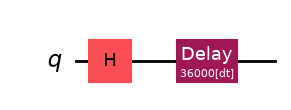

1 pulse (echo):


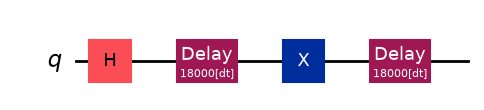

XY4:


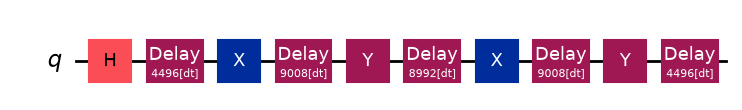

In [6]:
backend, _ = execution.get_primitives(backend_name)
dt, granularity = enc.timing(backend)
print(
    f"dt = {dt * 1e9:.4f} ns, delays are a multiple of {granularity} dt = {granularity * dt * 1e6:.4f} us"
)

wait = 8.0  # microseconds
for kind in ops.ARMS:
    print(ops.NAMES[kind] + ":")
    circuit = enc.build_circuit(wait, ops.pulse_train(kind, wait), dt, granularity)
    fig = circuit.draw("mpl")
    display(fig)
    plt.close(fig)  # keep the inline backend from drawing it a second time

The delays in the XY4 circuit have the lengths of the pieces above, in dt.

The circuits are **compiled** (`transpile_for`) with the optimizer **off**. Compiling translates a circuit into the gates that a device supports. The **optimizer** is a step of the compiler that rewrites a circuit into a shorter one that does the same thing, and "flip, wait, flip back" is what it is built to remove. With it on, it would delete the pulses we want to test.

### The noise as circuit parameters

On the simulator, the frequency noise is added to the circuit as phase rotations, one after each piece of the wait: `rz(shift * duration)`, where `shift` is the offset of the block that the piece belongs to. A new block of fast noise begins every $20\,\mu$s, so the circuit has one `shift` parameter per block. The echo circuit for $30\,\mu$s shows it. The pulse is at $15\,\mu$s and a new block begins at $20\,\mu$s, so the wait has three pieces.

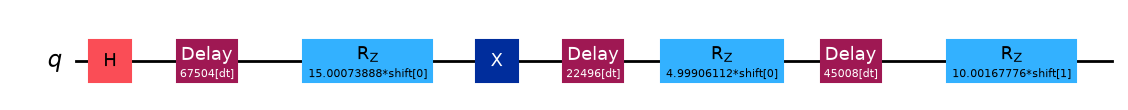

parameters: ['shift[0]', 'shift[1]']


In [7]:
total = 30.0
circuit = enc.build_circuit(
    total, ops.pulse_train("echo", total), dt, granularity, noise=True
)
fig = circuit.draw("mpl")
display(fig)
plt.close(fig)
print("parameters:", [str(p) for p in circuit.parameters])

The pulses are ordinary gates in the circuit, and the noise is added to the same circuit. Nothing in the code says that the echo should cancel the noise. The cancellation happens because $X\,R_Z(a)\,X = R_Z(-a)$, the rule of Step 1.

Each `shift` parameter is bound to a different value in every **member** of an ensemble of 256 noise realizations (a member is one possible draw of all the offsets of a run), and the Estimator averages the result. The values are the same for every circuit, so the curves of the three sequences see the same noise.

## Stop and think: what did the encoding decide?

**1. Why are the pulses not at the ends of the wait?**

*Answer.* They sit at the centers of equal slices, so the first and last free waits are half as long as the others. This makes the sequence symmetric, and the phase error cancels for a constant offset exactly ($\tfrac12 - 1 + 1 - 1 + \tfrac12 = 0$ in the XY4 check). Pulses at the very ends would leave a piece of the wait on one side with nothing to cancel it.

**2. What is different about the pulses on a real device?**

*Answer.* Here they are ideal gates that take no time, and the only error is the one we add (`pulse_error`). On hardware a pulse lasts tens of nanoseconds, and it adds to the idle time, so the free time between pulses is a little shorter than the idle time divided by the number of pulses. The real pulses also have their own errors.

**3. Why write the pulses into the circuit when the service can insert them?**

*Answer.* The Estimator of IBM Runtime can insert DD pulses into idle times itself. We use explicit gates so that the pulses are visible and under our control. The hardware path in Step 3 switches the service's DD on for comparison.

## Step 3: Execution

Every idle time of every sequence is one circuit, so three sequences of 41 idle times each make 123 circuits. They go out as **one job**: on hardware the queue wait is paid once per job, not once per circuit.

On the simulator the noise is added in three places:

1. Every delay relaxes with $T_1 = 100\,\mu$s and $T_2 = 70\,\mu$s.
2. The phase rotations of Step 2 add the slow and the fast frequency noise.
3. Every `x` and `y` gate has a **depolarizing error** of `pulse_error`: with probability $p$ the qubit is replaced by a completely random state, which has $\langle X\rangle = 0$, and with probability $1-p$ nothing happens. So the average $\langle X\rangle$ is $(1-p)$ times its value before the pulse.

**On hardware** the same explicit pulses run with the service's DD switched off (`options.dynamical_decoupling.enable = False`). With `runtime_dd = True` two more curves are measured. Their circuits hold only the delay, and the service inserts the pulses:

```python
estimator.options.dynamical_decoupling.enable = True
estimator.options.dynamical_decoupling.sequence_type = "XpXm"  # or "XY4"
```

`XpXm` is a train of $X$ and $-X$ pulses, which has the same effect on the phase as CPMG. This path is in the code but has not been run, because it needs a hardware account.

In [8]:
data = execution.run(
    ops.ARMS,
    t_max,
    points,
    backend_name,
    qubit,
    precision,
    pulse_error,
    runtime_dd,
)
print(f"\nTotal time: {data['seconds']:.0f} s")

  123 circuits in one job

 done

Total time: 15 s


The second run fixes the idle time at $50\,\mu$s and increases the number of $X$ pulses (CPMG) from 0 to 64, at three values of the pulse error. Pulse errors of $0.005$ and $0.02$ are larger than those of a good device, so the effect shows within 64 pulses.

In [9]:
sweep = execution.run_sweep(
    counts=(0, 1, 2, 4, 8, 16, 32, 64),
    pulse_errors=(0.0, 0.005, 0.02),
    total=50.0,
    backend_name=backend_name,
    qubit=qubit,
    precision=precision / 2,
)

  8 circuits in one job

 done


  8 circuits in one job

 done


  8 circuits in one job

 done


## Step 4: Analysis

### The fits

The fit minimizes the sum of squared differences between the data and the model of Step 1, with `scipy.optimize.curve_fit` as in the benchmarking notebook. The table shows the fitted decay time $\tau$ with its standard error, the fitted power $k$, and the decay time that the noise model implies for the same idle times (the same fit applied to the noise-free prediction `ops.predicted`). On the simulator the fitted and model times should agree within a few standard errors. The last two columns are the fitted $A$ and $B$ of the model. In an ideal experiment they are $1$ and $0$. Values within a few hundredths of these mean that preparation and measurement errors are small. The upper panel of the figure shows the data and fits, and the lower panel the residuals (data minus fit).

                      fit tau (us)  power  model tau (us)  amplitude  offset
no pulses              19.6 +/- 0.9    1.12            20.3       1.00    0.01
1 pulse (echo)         35.0 +/- 1.0    1.78            35.9       0.98    0.01
XY4                    71.1 +/- 3.7    0.96            67.5       1.00   -0.01


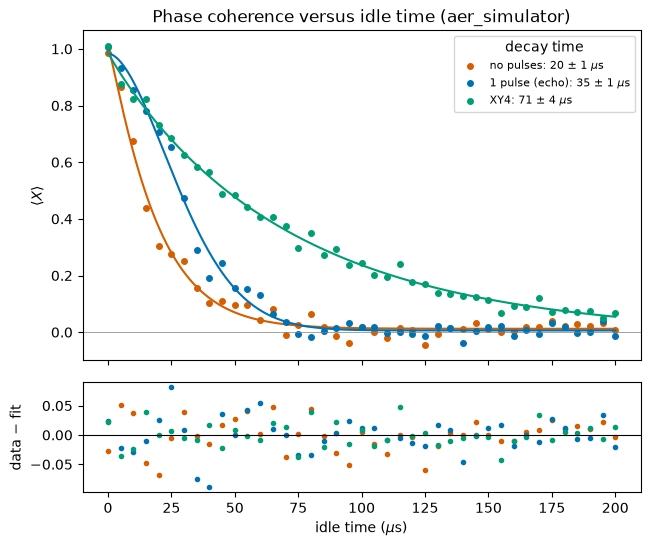

In [10]:
fits = analysis.fit_all(data)
analysis.print_table(data, fits)
fig = analysis.plot_fits(data, fits)

Three results stand out.

- **No pulses, about $20\,\mu$s.** The three rates add to a decay time of $18.3\,\mu$s in Step 1, which assumed a plain exponential. The curve is slightly flat at the start, so the fit gives $k \approx 1.1$ and $\tau \approx 20\,\mu$s.
- **One pulse, about $36\,\mu$s.** The echo removed the slow noise and the part of the fast noise that stays constant during half the wait. The power is close to $2$: the curve is flat at first and falls fast later. For short waits, the offset hardly changes between the two halves, and the echo works. For long waits, it changes, and the echo does not.
- **XY4, about $66\,\mu$s.** Four pulses per $8\,\mu$s are close together compared with the $20\,\mu$s of the fast noise, so almost all of it cancels. What is left is close to the limit $T_2 = 70\,\mu$s of the qubit itself. This curve decays slowest, and its fitted $\tau$ has the largest standard error, about $2$ to $3\,\mu$s.

### Why it works: the phase error in time

The figure draws the phase error $\varphi$ as it builds up during a $40\,\mu$s idle time, for one noise realization. Each column is one kind of offset, and the top row shows the offset itself in MHz. In the left column the offset is constant. In the right column it changes every $20\,\mu$s, as the fast noise of the simulator does. The lines in the bottom row are the three sequences. A line that ends at zero has no phase error at the end, so $\langle X\rangle = 1$ for that run. The legend gives the phase error at the end.

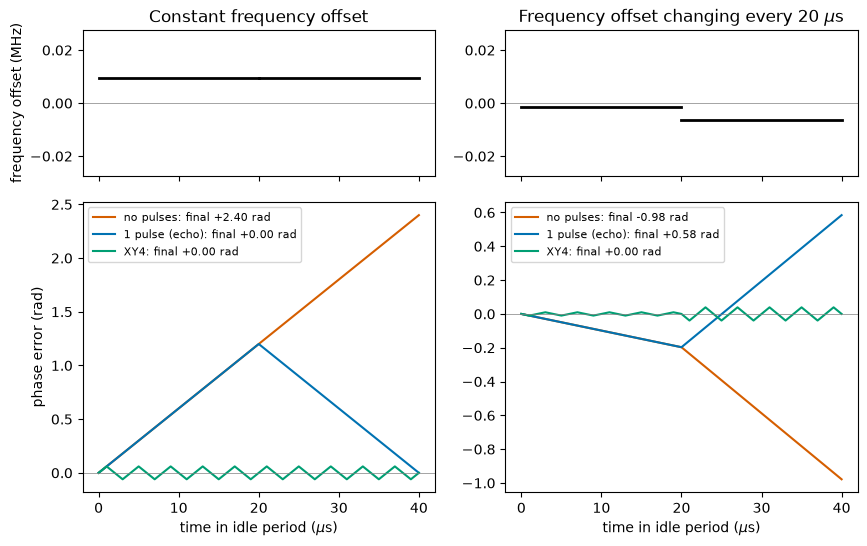

In [11]:
fig = analysis.plot_time_domain(total=40.0, member=3)

In the left column the echo ends at zero and so does XY4, which is the rule of Step 1: a constant offset cancels. Without pulses the phase error grows in a straight line. In the right column the echo no longer ends at zero, because the offset of the second $20\,\mu$s differs from the first. XY4 stays small throughout, because it flips every $2\,\mu$s, and the offset hardly changes within $2\,\mu$s. The phase error of XY4 climbs a little and comes back each cycle, and never gets far from zero. The decay in the fits is what the average of $\cos\varphi$ over many such realizations looks like.

### Counting pulses

The last figure shows $\langle X\rangle$ at a fixed $50\,\mu$s against the number of CPMG pulses. The points are the measurements and the lines are the noise-free prediction `ops.predicted("cpmg", ...)`. The table gives the prediction next to the data.

pulse error       0      1      2      4      8     16     32     64
0.0 data       0.08   0.19   0.31   0.48   0.45   0.49   0.49   0.49
0.0 model      0.08   0.19   0.32   0.46   0.48   0.49   0.49   0.49
0.005 data     0.08   0.19   0.33   0.46   0.46   0.46   0.41   0.33
0.005 model    0.08   0.19   0.32   0.45   0.46   0.45   0.42   0.36
0.02 data      0.10   0.19   0.31   0.41   0.41   0.36   0.26   0.15
0.02 model     0.08   0.19   0.31   0.43   0.41   0.35   0.26   0.13


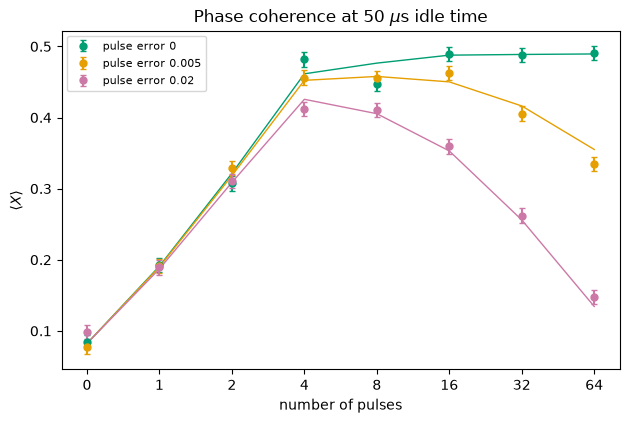

In [12]:
fig = analysis.plot_sweep(sweep)

counts = sweep["counts"]
print(f"{'pulse error':<12}" + "".join(f"{n:>7}" for n in counts))
for key, record in sweep["curves"].items():
    p = float(key)
    model = [
        ops.predicted("cpmg" if n else "none", sweep["total_us"], p, n or None)
        for n in counts
    ]
    print(f"{key + ' data':<12}" + "".join(f"{v:>7.2f}" for v in record["evs"]))
    print(f"{key + ' model':<12}" + "".join(f"{v:>7.2f}" for v in model))

With perfect pulses (pulse error 0) the curve rises until the pulses are much closer than the $20\,\mu$s of the noise (8 pulses are $6\,\mu$s apart), and then it stays at the ceiling $e^{-50/70} = 0.49$ set by the qubit's own $T_2$: the model gives 0.48 at 8 pulses and 0.49 from 16 on. With a pulse error $p$, every pulse costs a factor $1 - p$, so $n$ pulses cost $(1-p)^n$. The curve rises while the cancellation gains more than the pulses cost, passes a best number of pulses, and then falls. For $p = 0.02$ the best number is 4 (model 0.43), and the model falls to 0.13 at 64 pulses. For $p = 0.005$ the best number is 8 (model 0.46), and the curve falls to 0.36 at 64. A larger pulse error moves the best number to fewer pulses and lowers the best value.

### Example 3: the number of pulses that halves the signal

**Problem.** The cancellation is nearly complete from $n = 16$ pulses on, so $\langle X\rangle \approx e^{-50/70}(1-p)^n = 0.49\,(1-p)^n$. For $p = 0.02$, how many pulses reduce $\langle X\rangle$ to half of the ceiling?

**Solution.**

1. Set $(1-p)^n = 0.5$ and take the logarithm: $n \ln(0.98) = \ln 0.5$.
2. Divide: $n = \ln 0.5 / \ln 0.98 = (-0.693)/(-0.0202) \approx 34$.

**Check.** The model table above has $\langle X\rangle = 0.35$ for $n = 16$, $0.26$ for $n = 32$, and $0.13$ for $n = 64$ at $p = 0.02$. Half of $0.49$ is $0.245$, which lies between the values for 32 and 64, and closer to 32. So $n$ should be a little above 32. It is 34.

**Takeaway.** The number of pulses to use is the smallest one that removes the noise, not the largest one the circuit can hold. For a real device, $p$ is the error of one $X$ gate from the calibration page, and the best spacing is set by how fast the noise changes.

## Stop and think: reading the three figures

**1. Why does the echo curve have a power near 2 and XY4 a power near 1?**

*Answer.* The echo cancels the part of the noise that is constant for half the wait. For short waits that is nearly all of the fast noise, and for long waits little of it, so the curve is flat at first and then bends down. XY4 cancels it at every wait, so what is left is the plain $T_2$ decay, an exponential. The shape of the curve tells you how the pulses and the noise compare in time.

**2. The XY4 time is about 66 $\mu$s, below $T_2 = 70\,\mu$s. Where does the rest go?**

*Answer.* To the pulses. XY4 uses one pulse per $2\,\mu$s, and each costs a factor $1-p$ with $p = 0.001$, so the curve gets an extra factor $0.999^{t/2} \approx e^{-0.0005\,t}$. The rates add: $1/(1/70 + 0.0005) = 67.6\,\mu$s. The model column gives 67.5 $\mu$s, so the pulses account for the whole difference. The fitted value scatters around it by its standard error.

**3. Would the echo come close to 70 $\mu$s if the fast noise stayed constant for $200\,\mu$s instead of $20\,\mu$s?**

*Answer.* Yes. For waits up to $200\,\mu$s the offset would be constant, and the echo cancels a constant offset exactly. A longer memory of the noise means that fewer pulses are needed. This is the reason to measure the noise before choosing a sequence.

**4. A $20\,\mu$s wait has a pulse every $2\,\mu$s, with $p = 0.001$. What fraction of $\langle X\rangle$ do the pulses cost?**

*Answer.* There are 10 pulses, so the factor is $0.999^{10} = 0.990$, a cost of about 1%. Compare the noise: without pulses the same wait loses about half of $\langle X\rangle$.

## Reading the results

The numbers below are for the simulator with the default settings. Shot noise is random, so a rerun changes the fits by about their standard errors. The noise realizations are fixed (`ops.SEED`), so the model column does not change.

- **The decay times are about 20, 36, and 66 $\mu$s** for no pulses, the echo, and XY4, and the model says 20.3, 35.9, and 67.5 $\mu$s. The fits agree with the model within a few standard errors.
- **XY4 recovers about 95% of the $T_2$ limit of 70 $\mu$s.** The echo recovers about half of it, because the fast noise changes during a wait of $36\,\mu$s.
- **The fitted $A$ is close to 1 and $B$ close to 0** for all three, to within a few hundredths. We did not add any read-out error, so there is no preparation or measurement error for them to absorb.
- **Pulses cannot beat $T_2$.** No model curve lies above $e^{-t/T_2}$.
- **In the sweep at $50\,\mu$s, 8 perfect pulses are enough.** With a pulse error of 0.02 the best number is 4, and more pulses lower $\langle X\rangle$ to 0.13 at 64. The best number depends on how fast the noise changes and on how good the pulses are.

On hardware, expect:

- **A smaller gain.** The noise of a real qubit has a range of time scales, and the pulses have errors that are not depolarizing. The gain from the echo to XY4 is a measure of how much of the noise is fast.
- **Pulses that take time.** A pulse of tens of nanoseconds in a spacing of a few hundred nanoseconds is a visible fraction of the idle time.
- **A difference between `XpXm` and `XY4` in the runtime.** Both cancel slow noise. They differ in how pulse errors add up, because XY4 uses two axes. We have not measured that difference here.

## What to try next

1. Set `pulse_error = 0.01` and rerun the curves. Which of the three decay times changes, and why does the one-pulse echo hardly change at all?
2. In `ops.py` change `CORRELATION` to `5.0` and then to `80.0`. For which value does the echo get close to XY4? Predict the order before you run.
3. Change `FAST_SIGMA` to `0.0` (no fast noise). Which curves lie on top of each other now, and what are their decay times?
4. Change `XY4_CYCLE` to `40.0`, so the pulses are five times further apart. What happens to the XY4 decay time? Compare with the echo.
5. In the sweep, replace the pulse errors with `(0.0, 0.001, 0.002)`. Is there still a best number of pulses within 64? How many would you need to see one?
6. Use `ops.predicted` to find, for a pulse error of $0.002$ and $50\,\mu$s of idle time, the number of CPMG pulses that gives the largest $\langle X\rangle$.
7. Run on `ibm_rensselaer` with `qubit = 0` and `runtime_dd = True`. Does the service's `XpXm` or `XY4` come closer to your explicit XY4 curve?
8. Run the hardware experiment on two different qubits. Which qubit gains more from XY4 over the echo, and what does that say about the noise on each?

## Terms

| Term | Plain definition | First used |
|---|---|---|
| idle | no gate acts on the qubit | The problem |
| phase, phase error | angle between the two amplitudes; the part of it that is wrong | The problem |
| frequency offset | true qubit frequency minus the frequency the controls assume, in rad/$\mu$s | The problem |
| control electronics | the hardware that sends signals to the qubit | The problem |
| pulse | a short burst of control signal that applies an $X$ or $Y$ gate | The problem |
| dynamical decoupling (DD) | pulses inserted into idle time to cancel phase error | The problem |
| Hahn echo | DD with one pulse in the middle of the wait | The problem |
| XY4, cycle | the pulses $X, Y, X, Y$; one repeat of the four is a cycle | The problem, Step 1 |
| CPMG | $n$ evenly spaced $X$ pulses | Step 1 |
| global phase | an overall phase that no measurement can see | Step 1 |
| Lorentzian | a bell-shaped curve with long tails | Step 1 |
| compile, optimizer | translate a circuit to device gates; the step that shortens circuits | Step 2 |
| granularity | delays must be a multiple of 16 dt | Step 2 |
| member | one draw of all the noise offsets of a run | Step 2 |
| depolarizing error | with probability $p$ the qubit becomes a completely random state | Setup, Step 3 |
| standard error | typical size of the random error of a number | Setup |
| Aer, Estimator, IBM Runtime | the simulator, the tool that returns $\langle O\rangle$, and IBM's cloud service | Setup |